# Blue Mountains next day active fire modelling

Kian Luo, ML Engineer. This notebook audits and reconstructs the features, trains the baselines and XGBoost, and evaluates both within-season interpolation and strictly forward testing. Prediction scores and alert thresholds are displayed as percentages; they are uncalibrated scores, not fire probabilities. Raw 0-1 scores and binary observation labels remain unchanged for evaluation.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src').exists(), 'Open this notebook inside the delivered project'
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
import matplotlib.pyplot as plt
from audit_data import DATA, load_and_audit
from train_evaluate import FEATURES, split_weekly, split_chronological
print('Project:', ROOT.name)
print('Predictors:', {k: len(v) for k, v in FEATURES.items()})

Project: readiness-audit
Predictors: {'full': 23, 'conditions': 20}


## Audit and feature reconstruction

Labels, next-day alignment, neighbouring fire, rolling rainfall and completeness are checked before fitting. Reconstruction preserves the input files.

In [2]:
raw, data, audit = load_and_audit()
print(json.dumps(audit, indent=2))
from rebuild_extended import main as rebuild
rebuild()

{
  "sha256": "c9b4391f9616dce86172605419793e42a39a20adf1aecb30da11b4965afccb8b",
  "shape": [
    18980,
    39
  ],
  "missing_values": 0,
  "retained_rows": 15695,
  "retained_cells": 43,
  "retained_positives": 566,
  "dropped_positives": 12,
  "new_fire_positives": 132,
  "persistence_true_positives": 434,
  "rain_rolling_max_abs_error": {
    "3": 8.689208982559649e-06,
    "7": 8.970275814590423e-06,
    "30": 8.995644009246462e-06,
    "90": 9.705184083941276e-06
  },
  "extra_rain_history_day": "2019-06-30 verified against July 1 00 UTC raw precipitation",
  "short_90d_history_rows_retained": 3784,
  "target_month_positives": {
    "2019-07": 0,
    "2019-08": 4,
    "2019-09": 0,
    "2019-10": 0,
    "2019-11": 21,
    "2019-12": 493,
    "2020-01": 51,
    "2020-02": 9,
    "2020-03": 0,
    "2020-04": 0,
    "2020-05": 0,
    "2020-06": 0
  },
  "checks": [
    "unique keys",
    "finite complete inputs",
    "one day target shift",
    "labels reconstructed",
    "fire_to

## Define the prediction and splits

The target is one or more eligible FIRMS detections in a cell on the following UTC day. Interleaved weekly partitions use future weeks and measure interpolation. The forward split is the evidence relevant to later dates. Date groups always contain every retained cell.

In [3]:
for name, role in [('Weekly holdout', split_weekly(data)), ('Forward test', split_chronological(data))]:
    print(name)
    print(data.assign(partition=role).groupby('partition').fire_positive.agg(['size','sum','mean']).to_string())
print('Full feature contract:', FEATURES['full'])

Weekly holdout
            size  sum      mean
partition                      
buffer      1333   55  0.041260
test        2580  107  0.041473
train       9202  317  0.034449
validation  2580   87  0.033721
Forward test
            size  sum      mean
partition                      
buffer       172   46  0.267442
test        7740   45  0.005814
train       7181  230  0.032029
validation   602  245  0.406977
Full feature contract: ['temperature_max_c', 'temperature_mean_c', 'temperature_min_c', 'dewpoint_mean_c', 'relative_humidity_min_pct', 'relative_humidity_mean_pct', 'wind_speed_max_ms', 'wind_speed_mean_ms', 'precipitation_sum_mm', 'precipitation_3d_mm', 'precipitation_7d_mm', 'precipitation_30d_mm', 'precipitation_90d_mm', 'days_since_rain_5mm', 'slope_mean_deg', 'aspect_sin', 'aspect_cos', 'elevation_mean_m', 'elevation_min_m', 'elevation_max_m', 'fire_today', 'fire_neighbour_today', 'fire_days_last_7']


## Train and tune

Twelve fixed XGBoost configurations and four Logistic Regression regularisation values are scored on validation only. The threshold maximises validation precision subject to recall at least 0.80. Each outer fold has its own validation partition, scaler, class weights, early stopping and threshold. Test results do not guide any fitted parameter.

In [4]:
import train_evaluate
train_evaluate.main()

weekly_holdout [('prevalence', 0.0415, 0.0), ('persistence', 0.5708, 0.766), ('lr_full', 0.743, 0.766), ('lr_conditions', 0.2596, 0.71), ('xgb_full', 0.8237, 0.766), ('xgb_full_platt', 0.8237, 0.766), ('xgb_conditions', 0.5552, 0.879), ('xgb_conditions_platt', 0.5552, 0.879)]
chronological [('prevalence', 0.0058, 0.0), ('persistence', 0.0808, 0.289), ('lr_full', 0.1298, 0.178), ('lr_conditions', 0.0053, 0.733), ('xgb_full', 0.1859, 0.289), ('xgb_full_platt', 0.1859, 0.289), ('xgb_conditions', 0.0096, 0.311), ('xgb_conditions_platt', 0.0096, 0.311)]
blocked_fold_0 [('prevalence', 0.0414, 0.0), ('persistence', 0.6528, 0.803), ('lr_full', 0.7332, 0.905), ('lr_conditions', 0.2102, 0.847), ('xgb_full', 0.7246, 0.825), ('xgb_conditions', 0.2217, 0.628)]
blocked_fold_1 [('prevalence', 0.026, 0.0), ('persistence', 0.4194, 0.663), ('lr_full', 0.4878, 0.744), ('lr_conditions', 0.1979, 0.791), ('xgb_full', 0.5261, 0.535), ('xgb_conditions', 0.206, 0.849)]
blocked_fold_2 [('prevalence', 0.0357, 0.

## Evaluate rankings and classification errors

Average precision is the main metric. Trapezoidal PR area is saved separately. New-fire evaluation keeps all cells without a detection on the feature day; this is a detection-state transition, not verified ignition.

In [5]:
metrics = pd.read_csv(ROOT / 'output/results/metrics.csv')
cols = ['experiment','model','view','average_precision','precision','recall','f1','brier','tp','fp','fn','tn']
print(metrics[metrics.experiment.isin(['weekly_holdout','chronological'])][cols].to_string(index=False))
from make_figures import main as make_figures
make_figures()

    experiment                model     view  average_precision  precision   recall       f1    brier  tp   fp  fn   tn
weekly_holdout           prevalence      all           0.041473   0.000000 0.000000 0.000000 0.039802   0    0 107 2473
weekly_holdout           prevalence new_fire           0.010130   0.000000 0.000000 0.000000 0.010618   0    0  25 2443
weekly_holdout          persistence      all           0.570771   0.732143 0.766355 0.748858 0.021318  82   30  25 2443
weekly_holdout          persistence new_fire           0.010130   0.000000 0.000000 0.000000 0.010130   0    0  25 2443
weekly_holdout              lr_full      all           0.742979   0.713043 0.766355 0.738739 0.043250  82   33  25 2440
weekly_holdout              lr_full new_fire           0.140379   0.166667 0.040000 0.064516 0.033557   1    5  24 2438
weekly_holdout        lr_conditions      all           0.259595   0.177570 0.710280 0.284112 0.110876  76  352  31 2121
weekly_holdout        lr_conditions new_

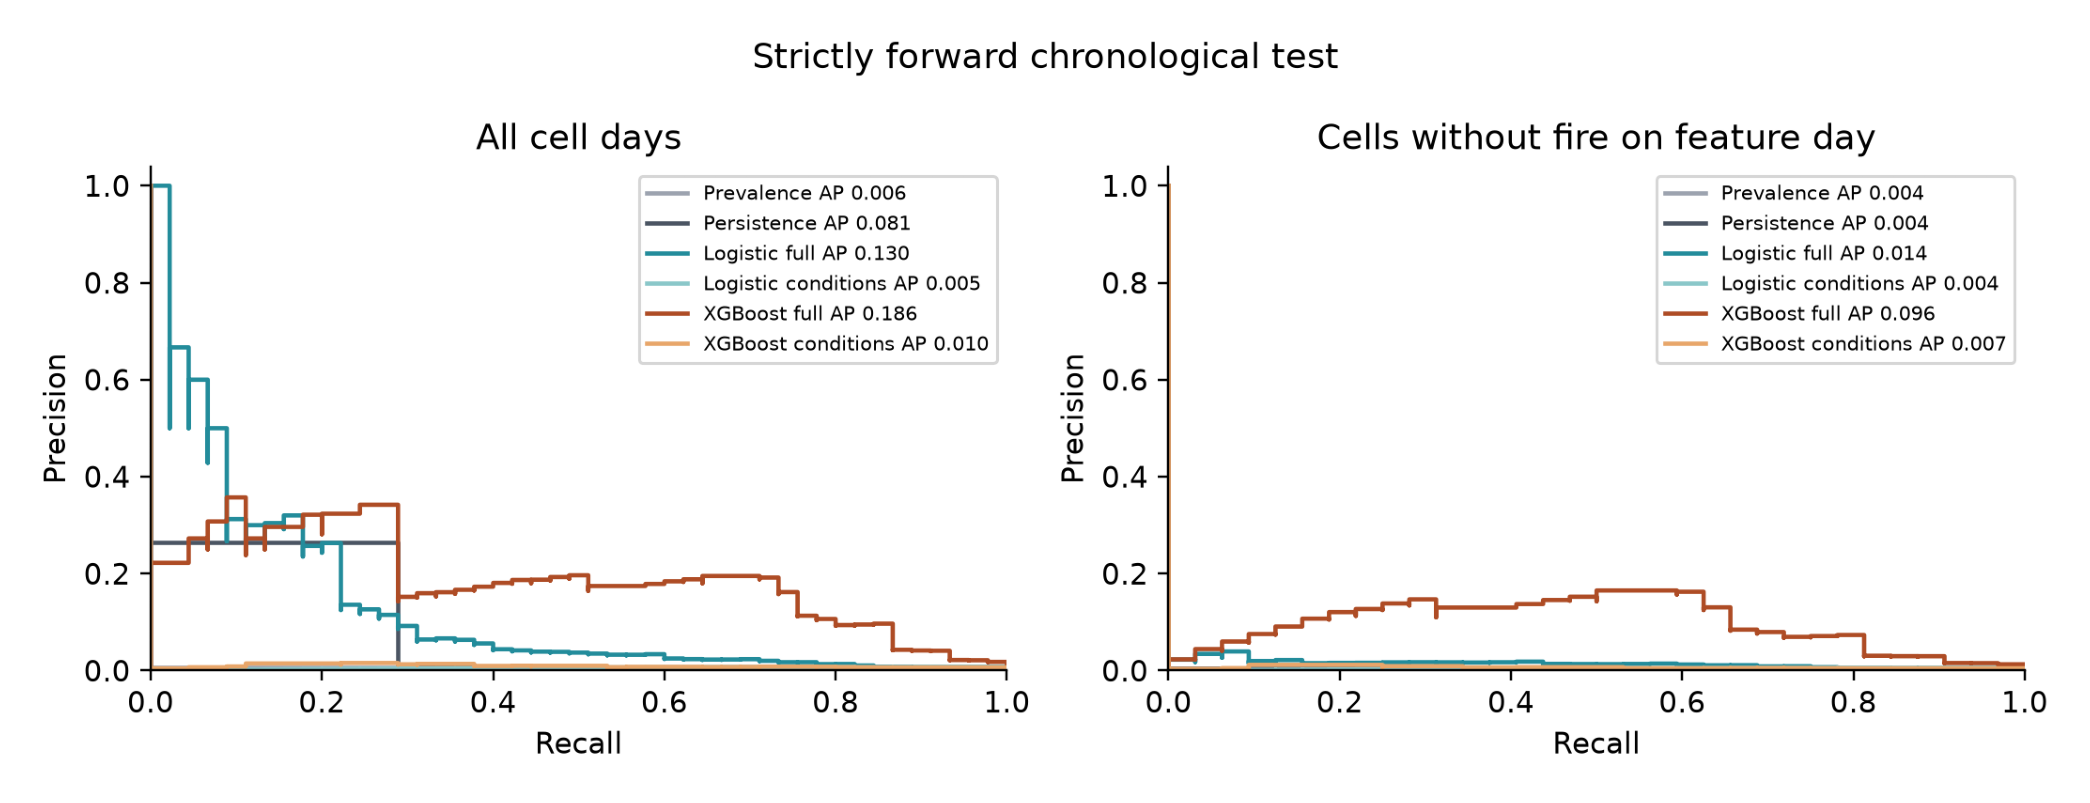

In [6]:
plt.figure(figsize=(12,5))
plt.imshow(plt.imread(ROOT / 'output/figures/02_pr_chronological.png'))
plt.axis('off')
plt.show()

## Blocked cross validation and sensitivity

The five outer test slots cover every retained row exactly once. Results remain correlated within one fire season. Three-day purging is a sensitivity analysis; seven-day symmetric purging removes the inner validation weeks and is not estimable with this rotation.

In [7]:
cv = metrics[metrics.experiment.str.startswith('blocked_fold_')]
print(cv.groupby(['model','view'])[['average_precision','recall','precision','brier']].agg(['mean','std']).to_string())
print((ROOT / 'output/results/uncertainty.json').read_text())

                        average_precision              recall           precision               brier          
                                     mean       std      mean       std      mean       std      mean       std
model          view                                                                                            
lr_conditions  all               0.226379  0.096959  0.776461  0.190956  0.147307  0.041699  0.113054  0.018875
               new_fire          0.072913  0.071009  0.732146  0.164641  0.039186  0.011995  0.107102  0.019967
lr_full        all               0.676282  0.107500  0.798649  0.072426  0.595899  0.184300  0.039622  0.008120
               new_fire          0.175755  0.057267  0.313135  0.196772  0.216462  0.102279  0.032965  0.007461
persistence    all               0.591023  0.100490  0.760411  0.055932  0.761390  0.084771  0.016792  0.002803
               new_fire          0.008728  0.000865  0.000000  0.000000  0.000000  0.000000  0.008728  0

## Probability quality and explanation

Platt calibration is exploratory and uses the same validation weeks as tuning. Native exact TreeSHAP is evaluated at the selected tree count and checked for additivity in log-odds units. Correlated covariates and the single season limit causal interpretation.

[
  {
    "experiment": "weekly_holdout",
    "model": "xgb_full",
    "raw_brier": 0.020144576206803322,
    "calibrated_brier": 0.01384444136733287,
    "calibration_slope": 1.0200120587711468,
    "validation_prevalence": 0.03372093023255814
  },
  {
    "experiment": "weekly_holdout",
    "model": "xgb_conditions",
    "raw_brier": 0.04086223244667053,
    "calibrated_brier": 0.02643760865301395,
    "calibration_slope": 0.7039108484575048,
    "validation_prevalence": 0.03372093023255814
  },
  {
    "experiment": "chronological",
    "model": "xgb_full",
    "raw_brier": 0.019192630425095558,
    "calibrated_brier": 0.01019369722956518,
    "calibration_slope": 0.7951087551590511,
    "validation_prevalence": 0.4069767441860465
  },
  {
    "experiment": "chronological",
    "model": "xgb_conditions",
    "raw_brier": 0.04574215039610863,
    "calibrated_brier": 0.08637370708025183,
    "calibration_slope": 1.3978259261876085,
    "validation_prevalence": 0.4069767441860465
  }
]

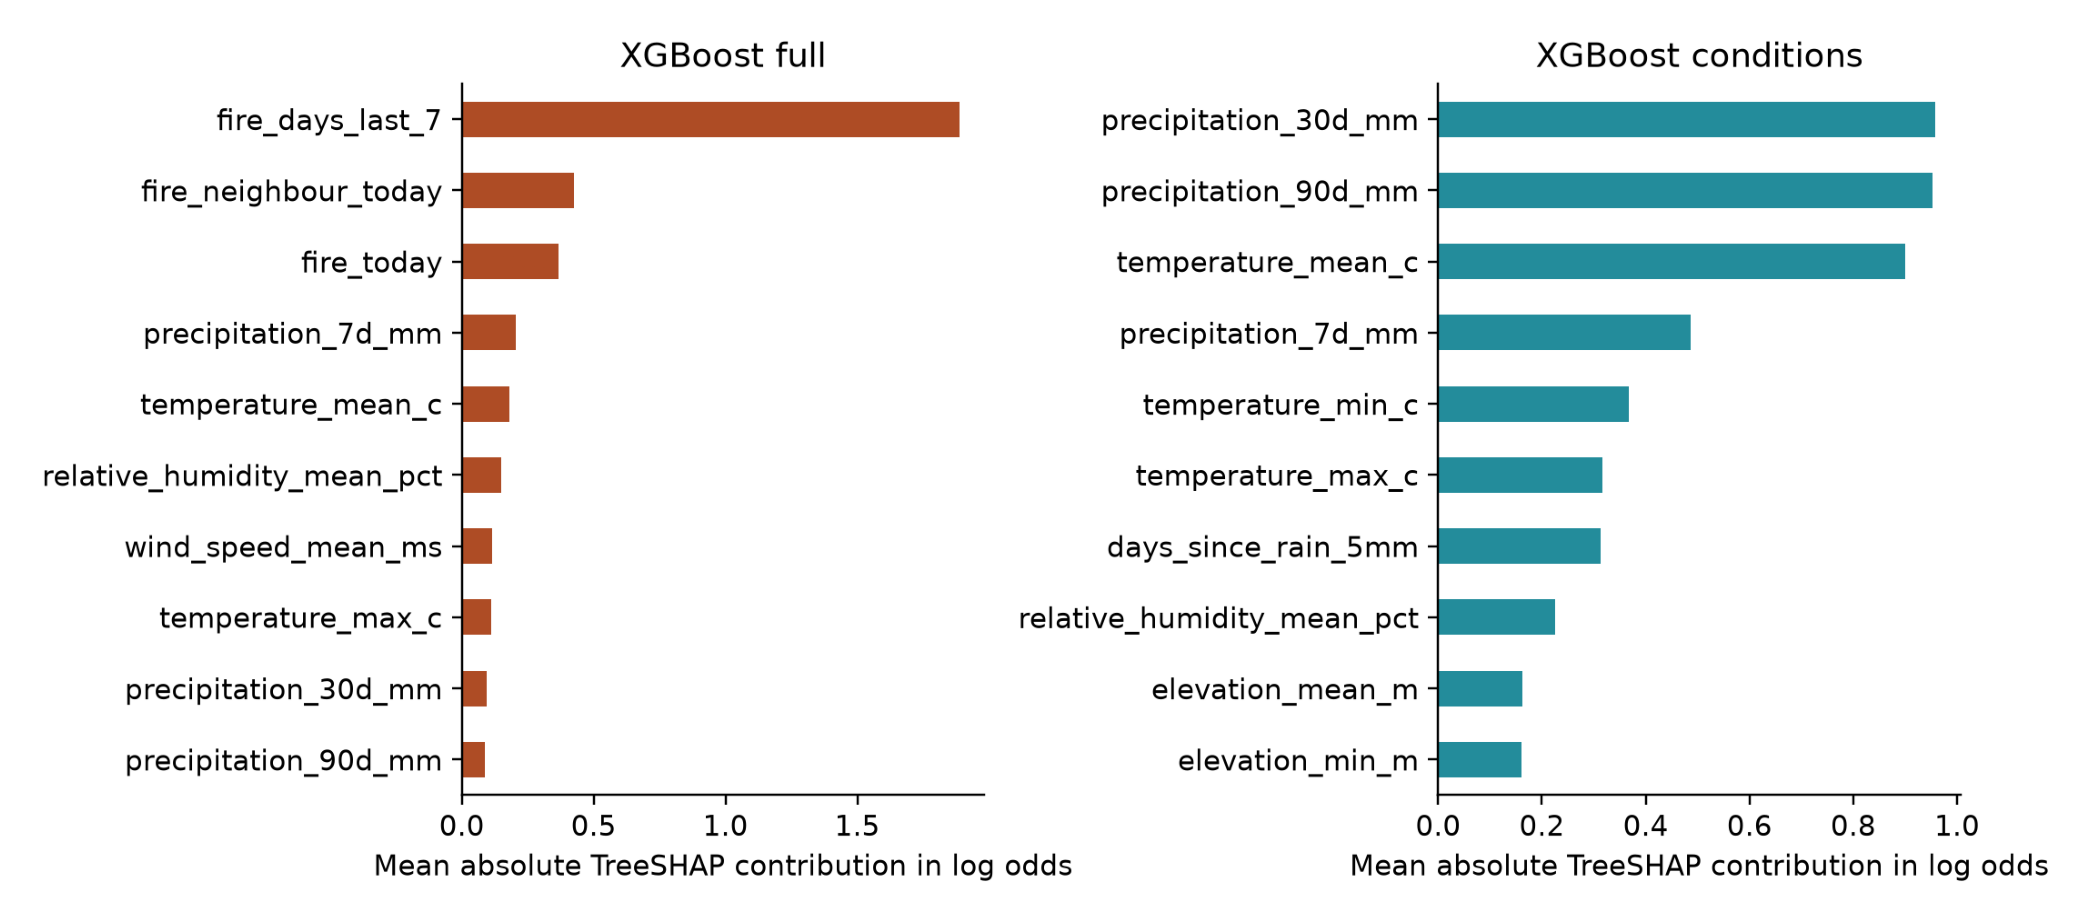

In [8]:
print((ROOT / 'output/results/calibration.json').read_text())
plt.figure(figsize=(12,6))
plt.imshow(plt.imread(ROOT / 'output/figures/06_shap_importance.png'))
plt.axis('off')
plt.show()

## Verify saved results and inference

This independently recomputes metric counts and AP, verifies date separation and outer test coverage, checks saved-model prediction parity, and requires the exact input feature schema.

In [9]:
from verify_results import main as verify
verify()
example = pd.read_csv(ROOT / 'output/example_scores.csv').head()
columns = ['grid_id','feature_date','target_date','model_score_percent','threshold_percent','alert','forecast_horizon_days']
print(example[columns].to_string(index=False, formatters={name: lambda value: f'{value:.2f}%' for name in ['model_score_percent','threshold_percent']}))
print('Percentages are uncalibrated model scores, not fire probabilities. Alerts use the unrounded raw score.')

{
  "passed": true,
  "metric_rows_checked": 126,
  "prediction_rows_checked": 226228,
  "percentage_rows_checked": 226228,
  "outer_test_coverage": 15695,
  "saved_model_parity_rows": 41280,
  "checks": [
    "confusion counts and AP independently recomputed",
    "weekly specification counts",
    "all cells grouped by date",
    "nested purging at 1 and 3 days",
    "strict forward target feature date separation",
    "saved UBJ predictions equal evaluation scores",
    "inference rejects missing feature",
    "new fire subset uses feature day state only",
    "percentage columns equal raw scores times 100",
    "alerts use unrounded raw scores",
    "accuracy precision recall F1 Brier and ranking metrics independently recomputed"
  ]
}
grid_id feature_date target_date model_score_percent threshold_percent  alert  forecast_horizon_days
 G01_05   2020-01-02  2020-01-03              13.38%            86.14%      0                      1
 G01_06   2020-01-02  2020-01-03              38

## Interpretation and unobserved human activity

The evidence supports within-season ranking improvement over prevalence and persistence. The strict forward test has only 45 positive cell-days and detects no new-fire positives with the full model at its validation threshold. Deliberate or accidental ignition, recreation, land-management actions and suppression are not explicit model inputs. Historical labels can contain their effects, but the model cannot anticipate a specific unobserved action. A low score does not establish safety. Multiple independently heldout seasons, event grouping, complete fuel data and point-in-time weather availability are needed before a stronger use claim.

## Forecast horizon

Each prediction concerns the next UTC day only. If fire is detected today, the full model uses that observation to score continued or spreading fire tomorrow. With newly observed weather and fire state tomorrow, the model can be run again for the following day. This is rolling next-day prediction, not a two- or three-day forecast issued today. True two-/three-day forecasts require horizon-specific labels, training and time-safe evaluation. Do not reuse tomorrow's score for later days, insert predicted fire states as observed facts, or add/multiply these uncalibrated scores to obtain a multi-day probability. See docs/FORECAST_HORIZONS.md.